In [124]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [125]:
# Load Airbnb dataset

df = pd.read_csv('/content/AB_NYC_2019.csv')

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [126]:
# Dataset dimensions

print("Dataset shape:", df.shape)

# Column names

print("\nColumn names:")
print(df.columns.tolist())

# Dataset information

print("\nDataset information:")
df.info()

Dataset shape: (48895, 16)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude         

In [127]:
# Statistical summary

display(df.describe())

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [128]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check data types
print("\nColumn data types:")
print(df.dtypes)

Missing values:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Number of duplicate rows: 0

Column data types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                      

In [129]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove unnecessary columns
df = df.drop(columns=[
    'id',
    'name',
    'host_id',
    'host_name',
    'last_review'
])

# Fill missing review values with 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Display cleaned dataset
print("\nCleaned dataset shape:", df.shape)
display(df.head())

Missing values after cleaning:
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

Cleaned dataset shape: (48895, 11)


,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [130]:
# Detect outliers using the IQR method

columns = ['price', 'minimum_nights']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print("\nColumn:", col)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of outliers:", len(outliers))


Column: price
Lower bound: -90.0
Upper bound: 334.0
Number of outliers: 2972

Column: minimum_nights
Lower bound: -5.0
Upper bound: 11.0
Number of outliers: 6607


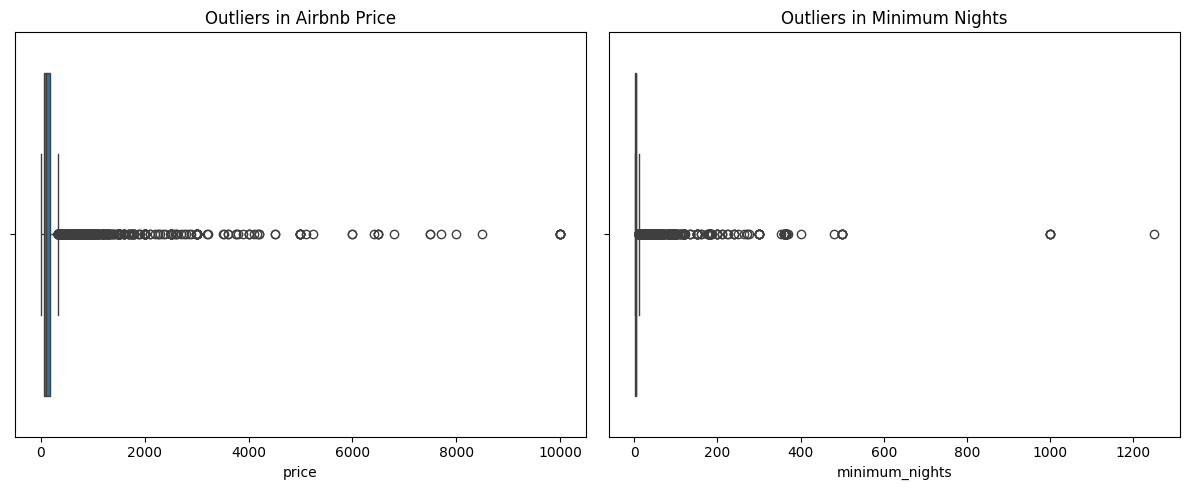

In [131]:
# Boxplots to visualize outliers

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'])
plt.title("Outliers in Airbnb Price")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['minimum_nights'])
plt.title("Outliers in Minimum Nights")

plt.tight_layout()
plt.show()

In [132]:
# Apply IQR-based outlier capping

columns = ['price', 'minimum_nights']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values outside the IQR limits
    df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    print(col)
    print("Lower limit:", lower_bound)
    print("Upper limit:", upper_bound)
    print("Outlier treatment completed.\n")

print("Dataset shape after outlier treatment:", df.shape)

price
Lower limit: -90.0
Upper limit: 334.0
Outlier treatment completed.

minimum_nights
Lower limit: -5.0
Upper limit: 11.0
Outlier treatment completed.

Dataset shape after outlier treatment: (48895, 11)


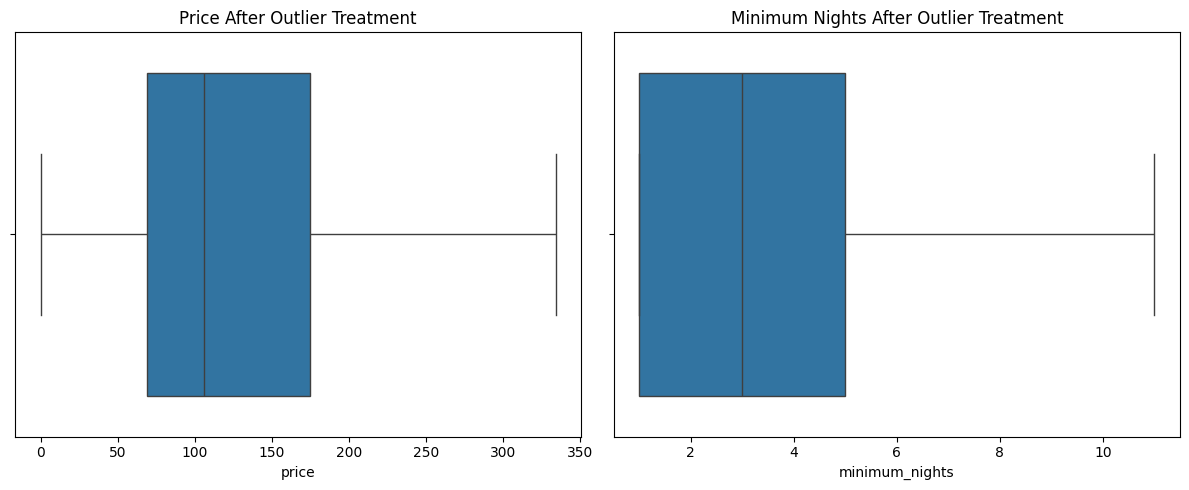

In [133]:
# Visualize data after outlier treatment

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'])
plt.title("Price After Outlier Treatment")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['minimum_nights'])
plt.title("Minimum Nights After Outlier Treatment")

plt.tight_layout()
plt.show()

In [134]:
# Separate input features and target variable

X = df.drop('price', axis=1)
y = df['price']

# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include=['object']).columns
numerical_columns = X.select_dtypes(exclude=['object']).columns

print("Categorical columns:")
print(list(categorical_columns))

print("\nNumerical columns:")
print(list(numerical_columns))

print("\nInput features shape:", X.shape)
print("Target variable shape:", y.shape)

Categorical columns:
['neighbourhood_group', 'neighbourhood', 'room_type']

Numerical columns:
['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Input features shape: (48895, 10)
Target variable shape: (48895,)


In [135]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (39116, 10)
Testing data: (9779, 10)


In [136]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Preprocess categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_columns)
    ],
    remainder='passthrough'
)

# Create Linear Regression pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [137]:
# Predict prices using test data
y_pred = model.predict(X_test)

print("Actual prices:")
print(y_test.head(10).values)

print("\nPredicted prices:")
print(y_pred[:10])

Actual prices:
[ 89  30 120 334 199 170  90  60 150  74]

Predicted prices:
[146.46554846  29.44077215 126.2474371  252.64127319 161.07823852
 165.89554124  89.51785005 112.28133704 220.77339463 135.551371  ]


In [138]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Model Evaluation Results")
print("-------------------------")
print("R2 Score:", r2)
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

Model Evaluation Results
-------------------------
R2 Score: 0.5234664361726609
Mean Absolute Error: 41.80047716403382
Mean Squared Error: 3277.85826781211
Root Mean Squared Error: 57.252583066723815


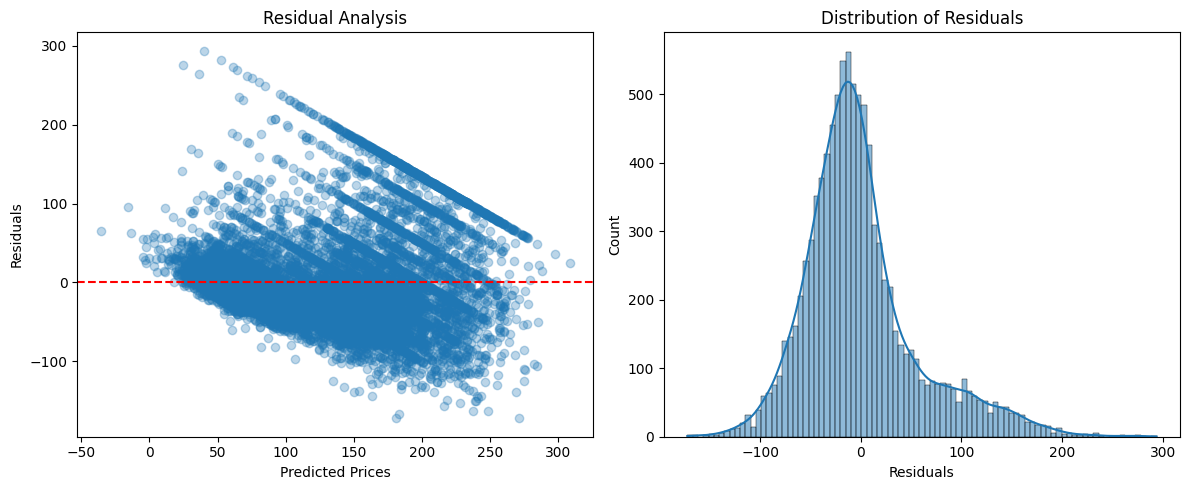

In [139]:
# Calculate residuals
residuals = y_test - y_pred

# Residual scatter plot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

# Residual distribution
plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True)
plt.xlabel("Residuals")
plt.title("Distribution of Residuals")

plt.tight_layout()
plt.show()

In [140]:
# Compare prediction errors for cheaper and expensive listings

results = pd.DataFrame({
    'Actual_Price': y_test,
    'Predicted_Price': y_pred
})

median_price = results['Actual_Price'].median()

results['Price_Category'] = np.where(
    results['Actual_Price'] <= median_price,
    'Cheaper Listings',
    'Expensive Listings'
)

results['Absolute_Error'] = abs(
    results['Actual_Price'] - results['Predicted_Price']
)

print(results.groupby('Price_Category')['Absolute_Error'].mean())

Price_Category
Cheaper Listings      30.092322
Expensive Listings    53.520612
Name: Absolute_Error, dtype: float64
